In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

In [2]:
def f(*x):
    return sum(xi**4 for xi in x)

##### Data

La somme quartique est en 10D. On trace une **coupe** : x2 = ... = x9 = 0, on fait varier x0 et x1.

In [3]:
x = np.arange(-2, 2, 0.01)
y = np.arange(-2, 2, 0.01)

X, Y = np.meshgrid(x, y)

Z = f(X, Y)

##### Affichage HeatMap (coupe x2 = ... = x9 = 0)

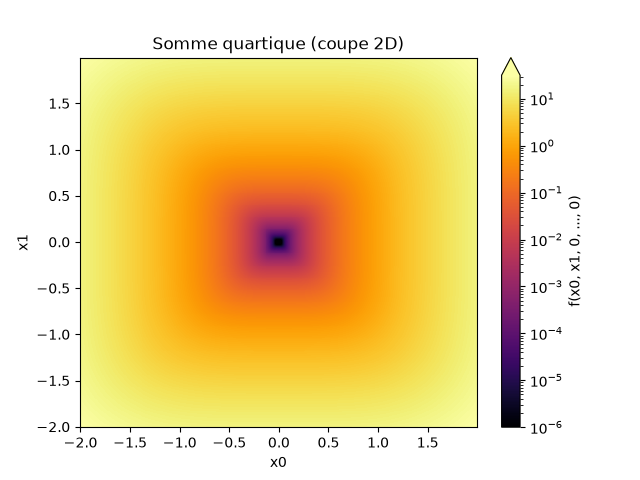

In [4]:
fig, ax = plt.subplots()

norm = LogNorm(vmin=1e-6, vmax=Z.max())
pcm = ax.pcolormesh(X, Y, Z, norm=norm, cmap="inferno", shading="auto")
fig.colorbar(pcm, ax=ax, extend="max", label="f(x0, x1, 0, ..., 0)")

ax.set_xlabel("x0")
ax.set_ylabel("x1")
ax.set_title("Somme quartique (coupe 2D)")

plt.show()

##### Pourquoi c'est plat près du minimum

Comparaison de x² et x⁴ près de 0 : x⁴ est beaucoup plus plat.

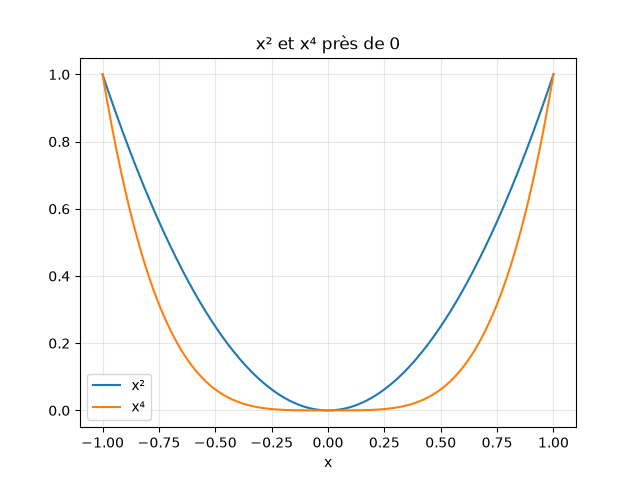

In [5]:
t = np.linspace(-1, 1, 400)

fig, ax = plt.subplots()
ax.plot(t, t**2, label="x²")
ax.plot(t, t**4, label="x⁴")
ax.set_xlabel("x")
ax.set_title("x² et x⁴ près de 0")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()

##### Recherche du minimum

In [6]:
from algo.neldermead import NelderMead
from utils.point import Point

def simplexe_initial(x, h=0.5):
    points = [Point(list(x))]
    for i in range(len(x)):
        y = list(x)
        y[i] += h
        points.append(Point(y))
    return points

def _f(p: Point)->float:
    return f(*p.values)

algo = NelderMead(simplexe_initial([1]*10), _f)
algo.compute(2000)

In [7]:
operations = ["Reflexion", "Expansion", "Contraction", "Homothetie"]
etats = [s for s in algo.history if s["operation"] in operations]

meilleurs = [min(s["points"], key=_f) for s in etats]
valeurs = [_f(p) for p in meilleurs]
iterations = [s["step"] for s in etats]

print("Meilleur point :", meilleurs[-1])
print("f =", valeurs[-1])

Meilleur point : Point([-0.00019144317890579308, -6.160665140552698e-05, -0.00013198514395784295, 0.0001637961205386836, 0.00012959627729098753, 7.617184609445964e-05, -0.00023742933020901702, 0.0001832326558849417, 4.919976013405954e-05, 0.0002563986026154207], Dimension: 10)
f = 1.1329416473960778e-14


##### Convergence de f

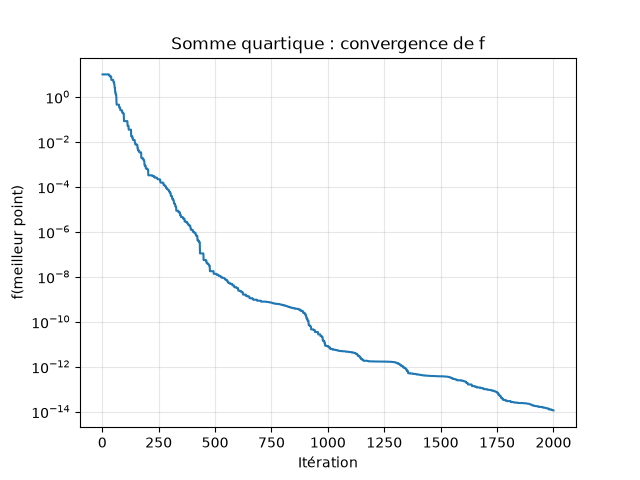

In [8]:
fig, ax = plt.subplots()

ax.semilogy(iterations, valeurs)
ax.set_xlabel("Itération")
ax.set_ylabel("f(meilleur point)")
ax.set_title("Somme quartique : convergence de f")
ax.grid(True, which="both", alpha=0.3)

plt.show()

##### Coordonnées du meilleur point (le minimum est en 0)

f devient minuscule bien avant que les coordonnées soient proches de 0.

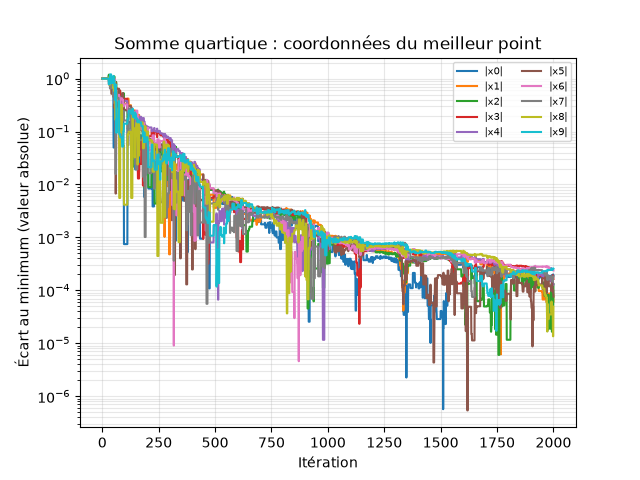

In [9]:
fig, ax = plt.subplots()

for i in range(10):
    ax.semilogy(iterations, [abs(p[i]) for p in meilleurs], label=f"|x{i}|")

ax.set_xlabel("Itération")
ax.set_ylabel("Écart au minimum (valeur absolue)")
ax.set_title("Somme quartique : coordonnées du meilleur point")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=7, ncol=2)

plt.show()